# Experiment 7: Demand-driven score exchange

This notebook compares the full-vector `MPI_Allgatherv` baseline with partial-vector, demand-driven score exchange. Both variants use the same four graphs, numerical parameters, in-edge-work partition, CPU allocation, and rank/thread layouts. Each configuration has one unrecorded warm-up and five measured runs. Dependency-plan construction is reported separately and is excluded from solve time.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'Makefile').exists():
    raise RuntimeError('Run this notebook from the extracted project root.')
RAW = ROOT / 'results' / 'vanda' / 'demand' / 'raw'
FIG = ROOT / 'results' / 'vanda' / 'demand' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
files = sorted(RAW.glob('*.csv'))
if not files:
    raise FileNotFoundError(f'No demand-exchange CSV files found in {RAW}')
df = pd.concat((pd.read_csv(path) for path in files), ignore_index=True)
print(f'Loaded {len(df)} measured runs from {len(files)} files.')

Loaded 160 measured runs from 8 files.


In [2]:
pattern = re.compile(r'demand-(google|berkstan|enwiki|uk)-(32|64)-(\d+x\d+)-(full|demand)-rep(\d+)')
parsed = df['run_id'].str.extract(pattern)
parsed.columns = ['dataset_key', 'total_cpus', 'layout', 'exchange_from_id', 'repetition']
df = pd.concat([df, parsed], axis=1)
df['total_cpus'] = pd.to_numeric(df['total_cpus'])
df['repetition'] = pd.to_numeric(df['repetition'])
labels = {'google': 'web-Google', 'berkstan': 'web-BerkStan', 'enwiki': 'enwiki-2013', 'uk': 'uk-2002'}
df['dataset_label'] = df['dataset_key'].map(labels)
assert df['run_id'].notna().all()
assert (df['score_exchange'] == df['exchange_from_id']).all()
expected = 4 * 2 * 2 * 2 * 5
print(f'Expected/observed measured rows: {expected}/{len(df)}')
display(df.groupby(['dataset_label', 'total_cpus', 'layout', 'score_exchange']).size().rename('runs').to_frame())

Expected/observed measured rows: 160/160


runs
dataset_label total_cpus layout score_exchange      
enwiki-2013   32         32x1   demand             5
                                full               5
                         4x8    demand             5
                                full               5
              64         64x1   demand             5
                                full               5
                         8x8    demand             5
                                full               5
uk-2002       32         32x1   demand             5
                                full               5
                         4x8    demand             5
                                full               5
              64         64x1   demand             5
                                full               5
                         8x8    demand             5
                                full               5
web-BerkStan  32         32x1   demand             5
                                full               5
                         4x8    demand             5
                                full               5
              64         64x1   demand             5
                                full               5
                         8x8    demand             5
                                full               5
web-Google    32         32x1   demand             5
                                full               5
                         4x8    demand             5
                                full               5
              64         64x1   demand             5
                                full               5
                         8x8    demand             5
                                full               5

## Correctness coverage

Formal jobs record convergence, the one-step residual, score-sum error, and configuration metadata. Serial/full-vector comparisons are exercised by `make test-parallel`; the independent full-graph NetworkX check for demand exchange is saved in `validation/reports/web-Google_networkx_demand.json`.

In [3]:
correctness = pd.Series({
    'measured runs': len(df),
    'converged runs': int(df['converged'].sum()),
    'maximum residual': df['residual'].max(),
    'maximum rank-sum error': df['rank_sum_error'].max(),
    'maximum iterations': int(df['iterations'].max()),
})
display(correctness.to_frame('value'))
assert df['converged'].eq(1).all()
assert df['residual'].max() <= 1e-10
assert df['rank_sum_error'].max() <= 1e-9

,value
measured runs,1.600000e+02
converged runs,1.600000e+02
maximum residual,8.241143e-13
maximum rank-sum error,2.986500e-12
maximum iterations,1.480000e+02


## Median controlled comparison

In [4]:
keys = ['dataset_label', 'total_cpus', 'layout', 'score_exchange']
metrics = [
    'solve_seconds', 'score_exchange_max_seconds', 'score_pack_max_seconds', 'dependency_seconds',
    'score_values_per_iteration', 'score_bytes_per_iteration',
    'score_state_bytes_max', 'peak_rss_bytes', 'iterations'
]
summary = df.groupby(keys, as_index=False)[metrics].median()
summary['score_MiB_per_iteration'] = summary['score_bytes_per_iteration'] / 2**20
summary['score_state_MiB_max'] = summary['score_state_bytes_max'] / 2**20
summary['peak_RSS_GiB_max_rank'] = summary['peak_rss_bytes'] / 2**30
display(summary[[*keys, 'solve_seconds', 'score_exchange_max_seconds', 'score_pack_max_seconds',
                 'dependency_seconds', 'score_MiB_per_iteration',
                 'score_state_MiB_max', 'peak_RSS_GiB_max_rank']].round(4))

,dataset_label,total_cpus,layout,score_exchange,solve_seconds,score_exchange_max_seconds,score_pack_max_seconds,dependency_seconds,score_MiB_per_iteration,score_state_MiB_max,peak_RSS_GiB_max_rank
0,enwiki-2013,32,32x1,demand,2.4467,0.3402,0.2842,0.3556,161.2393,35.3112,0.5440
1,enwiki-2013,32,32x1,full,3.1543,1.2970,0.0000,0.0000,994.1331,65.9011,0.5440
2,enwiki-2013,32,4x8,demand,3.4207,0.3098,0.3034,1.1432,59.4475,162.9263,0.6328
3,enwiki-2013,32,4x8,full,2.9083,0.6038,0.0000,0.0000,96.2064,74.0667,0.6328
4,enwiki-2013,64,64x1,demand,1.9682,0.8924,0.1202,0.2183,189.8554,20.2145,0.5385
5,enwiki-2013,64,64x1,full,2.6742,1.5902,0.0000,0.0000,2020.3350,65.0871,0.5385
6,enwiki-2013,64,8x8,demand,3.0311,0.4011,0.2407,1.1779,95.8916,97.0180,0.5812
7,enwiki-2013,64,8x8,full,3.3969,1.3930,0.0000,0.0000,224.4817,69.3393,0.5812
8,uk-2002,32,32x1,demand,3.8922,0.1215,0.1324,0.1834,41.5185,52.3521,1.7873
9,uk-2002,32,32x1,full,12.8833,9.6009,0.0000,0.0000,4380.3029,288.7831,1.7873


In [5]:
wide = summary.pivot(index=['dataset_label', 'total_cpus', 'layout'], columns='score_exchange')
comparison = pd.DataFrame(index=wide.index)
comparison['full_solve_s'] = wide['solve_seconds']['full']
comparison['demand_solve_s'] = wide['solve_seconds']['demand']
comparison['demand_speedup'] = comparison['full_solve_s'] / comparison['demand_solve_s']
comparison['volume_reduction'] = (
    wide['score_bytes_per_iteration']['full'] / wide['score_bytes_per_iteration']['demand']
)
comparison['demand_build_s'] = wide['dependency_seconds']['demand']
comparison['break_even_solves'] = np.where(
    comparison['full_solve_s'] > comparison['demand_solve_s'],
    comparison['demand_build_s'] / (comparison['full_solve_s'] - comparison['demand_solve_s']),
    np.inf,
)
display(comparison.round(4))

full_solve_s  demand_solve_s  demand_speedup  \
dataset_label total_cpus layout                                                 
enwiki-2013   32         32x1          3.1543          2.4467          1.2892   
                         4x8           2.9083          3.4207          0.8502   
              64         64x1          2.6742          1.9682          1.3587   
                         8x8           3.3969          3.0311          1.1207   
uk-2002       32         32x1         12.8833          3.8922          3.3100   
                         4x8           7.6089          4.1519          1.8326   
              64         64x1         11.6967          2.3475          4.9826   
                         8x8          12.6305          2.4014          5.2597   
web-BerkStan  32         32x1          0.4356          0.1454          2.9968   
                         4x8           0.3406          0.2135          1.5953   
              64         64x1          1.0297          0.4610          2.2336   
                         8x8           0.5877          0.2084          2.8197   
web-Google    32         32x1          0.7534          0.3521          2.1399   
                         4x8           0.4360          0.3871          1.1263   
              64         64x1          1.5701          0.5799          2.7075   
                         8x8           0.6263          0.2945          2.1265   

                                 volume_reduction  demand_build_s  \
dataset_label total_cpus layout                                     
enwiki-2013   32         32x1              6.1656          0.3556   
                         4x8               1.6183          1.1432   
              64         64x1             10.6414          0.2183   
                         8x8               2.3410          1.1779   
uk-2002       32         32x1            105.5025          0.1834   
                         4x8              15.8219          0.5922   
              64         64x1            202.6990          0.1247   
                         8x8              29.4421          0.3848   
web-BerkStan  32         32x1             31.5427          0.0224   
                         4x8              12.3272          0.0391   
              64         64x1             44.6815          0.0263   
                         8x8              17.6851          0.0308   
web-Google    32         32x1              6.5390          0.0414   
                         4x8               1.7299          0.1949   
              64         64x1             12.0400          0.0293   
                         8x8               2.4110          0.0757   

                                 break_even_solves  
dataset_label total_cpus layout                     
enwiki-2013   32         32x1               0.5025  
                         4x8                   inf  
              64         64x1               0.3092  
                         8x8                3.2201  
uk-2002       32         32x1               0.0204  
                         4x8                0.1713  
              64         64x1               0.0133  
                         8x8                0.0376  
web-BerkStan  32         32x1               0.0771  
                         4x8                0.3073  
              64         64x1               0.0463  
                         8x8                0.0813  
web-Google    32         32x1               0.1033  
                         4x8                3.9871  
              64         64x1               0.0296  
                         8x8                0.2282

## Interpretation

Demand-driven exchange improves 15 of 16 controlled comparisons. Median solve-time speedup ranges from 1.121x to 5.260x among the improvements. The only regression is enwiki-2013 at 32 CPUs with the 4x8 Hybrid layout: demand takes 3.421 s versus 2.908 s for full exchange (0.850x). In that configuration the score payload falls by only 1.62x, while packing takes 0.303 s, dependency construction takes 1.143 s outside solve time, and exchange-related state grows to 2.20x the baseline estimate. The evaluated demand implementation packs send values serially within each MPI rank, including Hybrid runs, so this stage does not use the OpenMP threads.

The largest benefit is uk-2002 at 64 CPUs with 8x8 Hybrid: 12.631 s falls to 2.401 s (5.260x). Its payload is reduced by 29.44x. MPI-only uk-2002 at 64 CPUs reduces payload by 202.70x and improves solve time by 4.983x. These results show that benefit follows remote-dependency sparsity, not graph size alone.

The one-time demand-plan build takes 0.022-1.178 s and is excluded from solve time. It is recovered within one solve for every improving configuration except Google 4x8 at 32 CPUs, which needs about four solves; the regressing enwiki 4x8 configuration has no break-even point under these measurements. Maximum-rank peak RSS is unchanged because it is a process high-water mark dominated by rank 0 loading the complete graph. The explicit exchange-state estimate is therefore more informative: demand uses less state in 13 of 16 configurations but more for Google 4x8, enwiki 4x8 at both CPU counts, and uk-2002 4x8.

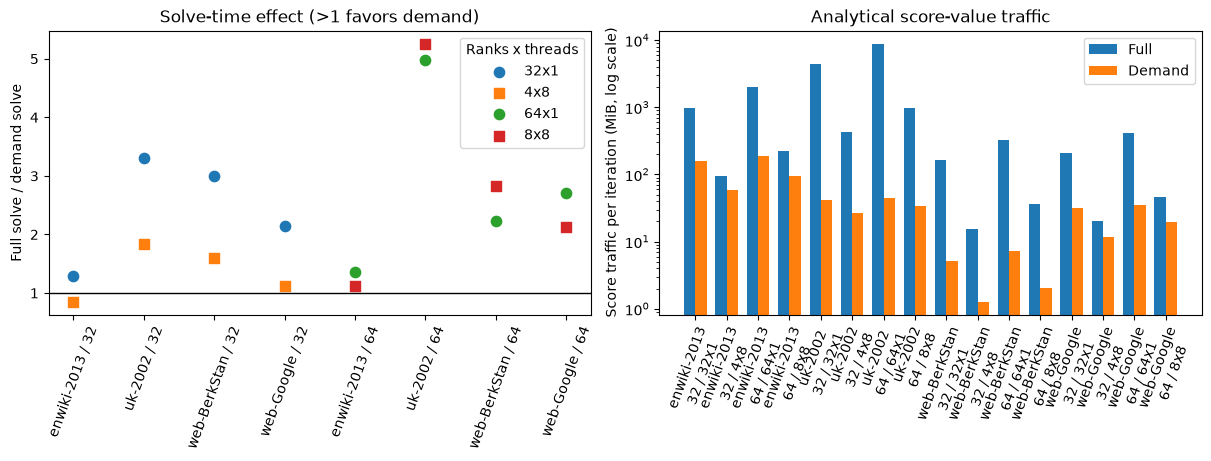

In [6]:
plot = comparison.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for layout, marker in [('32x1', 'o'), ('4x8', 's'), ('64x1', 'o'), ('8x8', 's')]:
    part = plot[plot['layout'] == layout]
    if not part.empty:
        axes[0].scatter(part['dataset_label'] + ' / ' + part['total_cpus'].astype(str),
                        part['demand_speedup'], label=layout, marker=marker, s=55)
axes[0].axhline(1, color='black', linewidth=1)
axes[0].set_ylabel('Full solve / demand solve')
axes[0].set_title('Solve-time effect (>1 favors demand)')
axes[0].tick_params(axis='x', rotation=70)
axes[0].legend(title='Ranks x threads')

x = np.arange(len(plot))
axes[1].bar(x - 0.18, wide['score_bytes_per_iteration']['full'] / 2**20, width=0.36, label='Full')
axes[1].bar(x + 0.18, wide['score_bytes_per_iteration']['demand'] / 2**20, width=0.36, label='Demand')
axes[1].set_yscale('log')
axes[1].set_ylabel('Score traffic per iteration (MiB, log scale)')
axes[1].set_title('Analytical score-value traffic')
axes[1].set_xticks(x, [f'{d}\n{c} / {l}' for d, c, l in wide.index], rotation=70)
axes[1].legend()
fig.savefig(FIG / 'demand_runtime_and_volume.png', dpi=180, bbox_inches='tight')
plt.show()

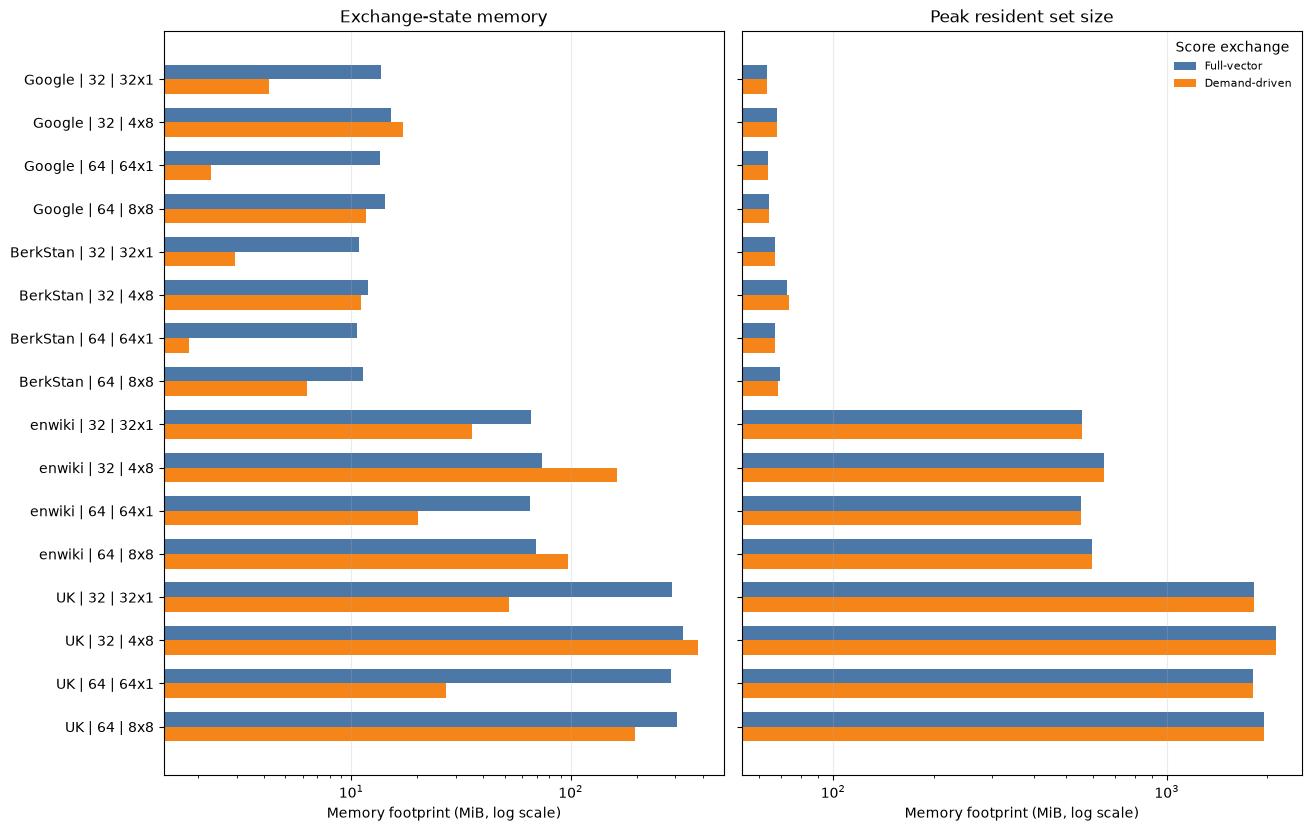

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 8.2), sharey=True, constrained_layout=True)
dataset_order = ['web-Google', 'web-BerkStan', 'enwiki-2013', 'uk-2002']
configuration_order = []
for dataset in dataset_order:
    configuration_order.extend([
        (dataset, 32, '32x1'), (dataset, 32, '4x8'),
        (dataset, 64, '64x1'), (dataset, 64, '8x8'),
    ])
memory = (summary.pivot(index=['dataset_label', 'total_cpus', 'layout'],
                        columns='score_exchange')
                  .reindex(pd.MultiIndex.from_tuples(
                      configuration_order,
                      names=['dataset_label', 'total_cpus', 'layout'])))
assert memory['score_state_MiB_max'].notna().all().all()
assert memory['peak_RSS_GiB_max_rank'].notna().all().all()
y = np.arange(len(memory))
bar_height = 0.34
short_names = {'web-Google': 'Google', 'web-BerkStan': 'BerkStan',
               'enwiki-2013': 'enwiki', 'uk-2002': 'UK'}
labels = [f'{short_names[dataset]} | {cpus} | {layout}' for dataset, cpus, layout in memory.index]
metrics = [
    ('score_state_MiB_max', 1.0, 'Exchange-state memory'),
    ('peak_RSS_GiB_max_rank', 1024.0, 'Peak resident set size'),
]
for ax, (metric, scale, title) in zip(axes, metrics):
    ax.barh(y - bar_height / 2, memory[metric]['full'] * scale, bar_height,
            color='#4C78A8', label='Full-vector')
    ax.barh(y + bar_height / 2, memory[metric]['demand'] * scale, bar_height,
            color='#F58518', label='Demand-driven')
    ax.set_xscale('log')
    ax.set_xlabel('Memory footprint (MiB, log scale)')
    ax.set_title(title)
    ax.grid(axis='x', alpha=0.25, zorder=0)
axes[0].set_yticks(y, labels)
axes[0].invert_yaxis()
axes[1].legend(frameon=False, fontsize=8, loc='upper right', title='Score exchange')
fig.savefig(FIG / 'demand_memory.png', dpi=180, bbox_inches='tight')
plt.show()

## End-to-end optimization waterfall

This controlled uk-2002 run summarizes the optimization pipeline on a graph with a stable historical serial baseline. The graph, numerical parameters, Vanda node, 32-CPU allocation, warm-up, and five measured repetitions are fixed. Serial uses one core; all parallel stages use the same 32 allocated cores. The parallel stages use the best fixed-32 layout for uk-2002, 2 MPI ranks × 16 OpenMP threads, except for the MPI-only stage.

,Series,Host,Median (s),CV (%),Min (s),Max (s),Gap vs same-node historical (%)
0,Historical UK strong baseline,IN-002,80.801866,0.582994,80.549118,81.703903,0.000000
1,Supplementary UK strong baseline,IN-015,61.541959,2.568607,61.485802,65.114889,-23.835968
2,UK waterfall baseline,IN-002,78.663030,0.137143,78.459670,78.706574,-2.647013


,Stage,MPI ranks x threads,Median solve time (s),Marginal reduction (s),Cumulative speedup
0,Serial,1 x 1,78.663,—,1.00x
1,MPI-only,32 x 1,13.415,65.248,5.86x
2,MPI+OpenMP,2 x 16,6.624,6.791,11.88x
3,In-edge partitioning,2 x 16,6.449,0.175,12.20x
4,On-demand exchange,2 x 16,4.121,2.328,19.09x


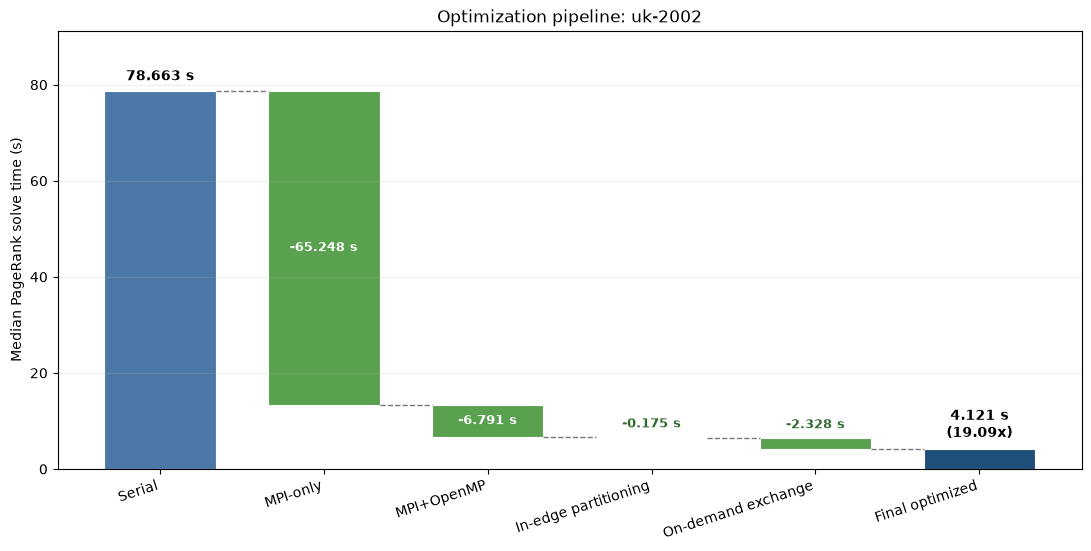

In [8]:
waterfall_raw = ROOT / 'results' / 'vanda' / 'waterfall_uk' / 'raw'
waterfall_fig = ROOT / 'results' / 'vanda' / 'waterfall_uk' / 'figures'
waterfall_fig.mkdir(parents=True, exist_ok=True)
waterfall_files = sorted(waterfall_raw.glob('*.csv'))
if not waterfall_files:
    raise FileNotFoundError(f'No controlled waterfall CSV found in {waterfall_raw}')
wf = pd.concat((pd.read_csv(path) for path in waterfall_files), ignore_index=True)
stages = ['serial', 'mpi-only', 'hybrid', 'in-edge', 'on-demand']
labels = ['Serial', 'MPI-only', 'MPI+OpenMP', 'In-edge partitioning', 'On-demand exchange']
configs = ['1 x 1', '32 x 1', '2 x 16', '2 x 16', '2 x 16']
wf['stage'] = wf['run_id'].str.extract(r'waterfall-uk-(serial|mpi-only|hybrid|in-edge|on-demand)-rep')
assert len(wf) == 25 and wf['stage'].notna().all()
assert wf.groupby('stage').size().reindex(stages).eq(5).all()
assert wf['converged'].astype(bool).all()
assert (wf['residual'] <= 1e-11).all() and (wf['rank_sum_error'].abs() <= 1e-10).all()

serial_values = wf.loc[wf['stage'].eq('serial'), 'solve_seconds']
historical_files = sorted((ROOT / 'results/vanda/raw').glob('*strong-uk.csv'))
historical = pd.concat((pd.read_csv(path) for path in historical_files), ignore_index=True)
historical_values = historical.loc[historical['mode'].eq('serial'), 'solve_seconds']
latest_files = sorted((ROOT / 'results/vanda/strong_full/raw').glob('*strong-full-uk-single.csv'))
latest = pd.concat((pd.read_csv(path) for path in latest_files), ignore_index=True)
latest_values = latest.loc[latest['mode'].eq('serial'), 'solve_seconds']

def stability_row(label, values, host):
    return {'Series': label, 'Host': host, 'Median (s)': values.median(),
            'CV (%)': 100 * values.std(ddof=1) / values.mean(),
            'Min (s)': values.min(), 'Max (s)': values.max()}

baseline_check = pd.DataFrame([
    stability_row('Historical UK strong baseline', historical_values,
                  ','.join(sorted(historical.loc[historical['mode'].eq('serial'), 'hostname'].unique()))),
    stability_row('Supplementary UK strong baseline', latest_values,
                  ','.join(sorted(latest.loc[latest['mode'].eq('serial'), 'hostname'].unique()))),
    stability_row('UK waterfall baseline', serial_values,
                  ','.join(sorted(wf.loc[wf['stage'].eq('serial'), 'hostname'].unique()))),
])
baseline_check['Gap vs same-node historical (%)'] = (
    100 * (baseline_check['Median (s)'] / historical_values.median() - 1)
)
display(baseline_check)

medians = wf.groupby('stage')['solve_seconds'].median().reindex(stages)
marginal = medians.shift(1) - medians
pipeline = pd.DataFrame({
    'Stage': labels, 'MPI ranks x threads': configs,
    'Median solve time (s)': medians.to_numpy(),
    'Marginal reduction (s)': marginal.to_numpy(),
    'Cumulative speedup': medians.iloc[0] / medians.to_numpy(),
})
pipeline_display = pipeline.copy()
pipeline_display['Median solve time (s)'] = pipeline_display['Median solve time (s)'].map(lambda value: f'{value:.3f}')
pipeline_display['Marginal reduction (s)'] = pipeline_display['Marginal reduction (s)'].map(lambda value: '—' if pd.isna(value) else f'{value:.3f}')
pipeline_display['Cumulative speedup'] = pipeline_display['Cumulative speedup'].map(lambda value: f'{value:.2f}x')
display(pipeline_display)

values = medians.to_numpy()
x = np.arange(len(values) + 1)
bottoms = np.r_[0.0, values[1:], 0.0]
heights = np.r_[values[0], values[:-1] - values[1:], values[-1]]
colors = ['#4C78A8'] + ['#59A14F'] * 4 + ['#1F4E79']
tick_labels = ['Serial'] + labels[1:] + ['Final optimized']
fig, ax = plt.subplots(figsize=(10.8, 5.4), constrained_layout=True)
ax.bar(x, heights, bottom=bottoms, width=0.68, color=colors, edgecolor='white', linewidth=0.8)
for index in range(len(values) - 1):
    ax.plot([index + 0.34, index + 1 - 0.34], [values[index], values[index]],
            color='#777777', linewidth=1, linestyle='--')
ax.plot([len(values) - 1 + 0.34, len(values) - 0.34], [values[-1], values[-1]],
        color='#777777', linewidth=1, linestyle='--')
ax.text(0, values[0] + values[0] * 0.02, f'{values[0]:.3f} s', ha='center', va='bottom', fontweight='bold')
for index in range(1, len(values)):
    if heights[index] < values[0] * 0.04:
        ax.text(index, bottoms[index] + heights[index] + values[0] * 0.018,
                f'-{heights[index]:.3f} s', ha='center', va='bottom',
                color='#2F6B2F', fontweight='bold', fontsize=9)
    else:
        ax.text(index, bottoms[index] + heights[index] / 2, f'-{heights[index]:.3f} s',
                ha='center', va='center', color='white', fontweight='bold', fontsize=9)
ax.text(len(values), values[-1] + values[0] * 0.02,
        f'{values[-1]:.3f} s\n({values[0] / values[-1]:.2f}x)',
        ha='center', va='bottom', fontweight='bold')
ax.set_xticks(x, tick_labels, rotation=18, ha='right')
ax.set_ylabel('Median PageRank solve time (s)')
ax.set_title('Optimization pipeline: uk-2002')
ax.grid(axis='y', alpha=0.22, zorder=0)
ax.set_ylim(0, values[0] * 1.16)
fig.savefig(waterfall_fig / 'pipeline_waterfall.png', dpi=200, bbox_inches='tight')
plt.show()

## Reproduce on Vanda

From the extracted project root on Vanda, submit the controlled demand-exchange suite and the UK optimization-pipeline run:

```bash
mkdir -p results/vanda/demand/logs
build_job=$(qsub -o "$PWD/results/vanda/demand/logs/build.out" \
  -v "PROJECT_DIR=$PWD" scripts/vanda/build_vanda.pbs)
scripts/vanda/submit_vanda_demand.sh "$PWD" "$build_job"
scripts/vanda/submit_vanda_waterfall_uk.sh "$PWD" "$build_job"
```

Fetch the completed `results/vanda/demand` and `results/vanda/waterfall_uk` directories to the same relative paths in the local project. No user-specific absolute path is required.